<a href="https://colab.research.google.com/github/Shree1785/CSL701-CE49-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Bhagyashree Shrikrishna Wagle

Batch : CE3

Roll Number : CE49



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Load the Mall Customer Segmentation dataset
df = pd.read_csv("/content/Mall_Customers.csv")

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()


Dataset Shape: (200, 5)

Column Names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

First Five Rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Select features for clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected Features:")
display(X.head())

print("\nScaled Data (First Five Rows):")
display(pd.DataFrame(
    X_scaled,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
).head())

print("\nScaled Data Shape:", X_scaled.shape)


Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Scaled Data (First Five Rows):


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Scaled Data Shape: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

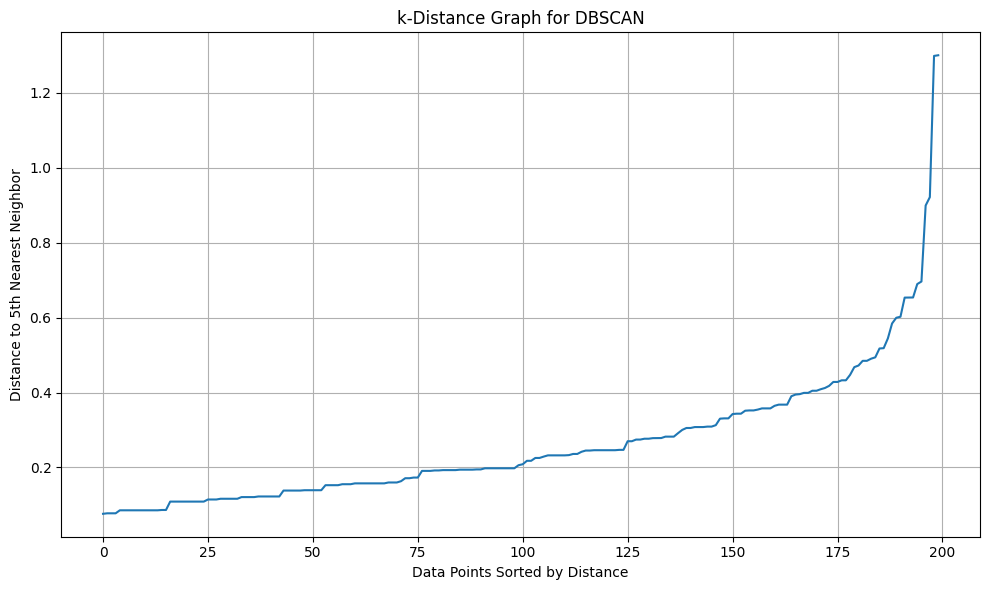

Inspect the elbow in the graph to select eps.


In [ ]:

# Set min_samples
min_samples = 5

# Calculate distances to nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort the distances to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(k_distances)

plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Inspect the elbow in the graph to select eps.")


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

DBSCAN clustering completed successfully!

Cluster Labels:
[-1  0]

First Five Rows with Cluster Labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


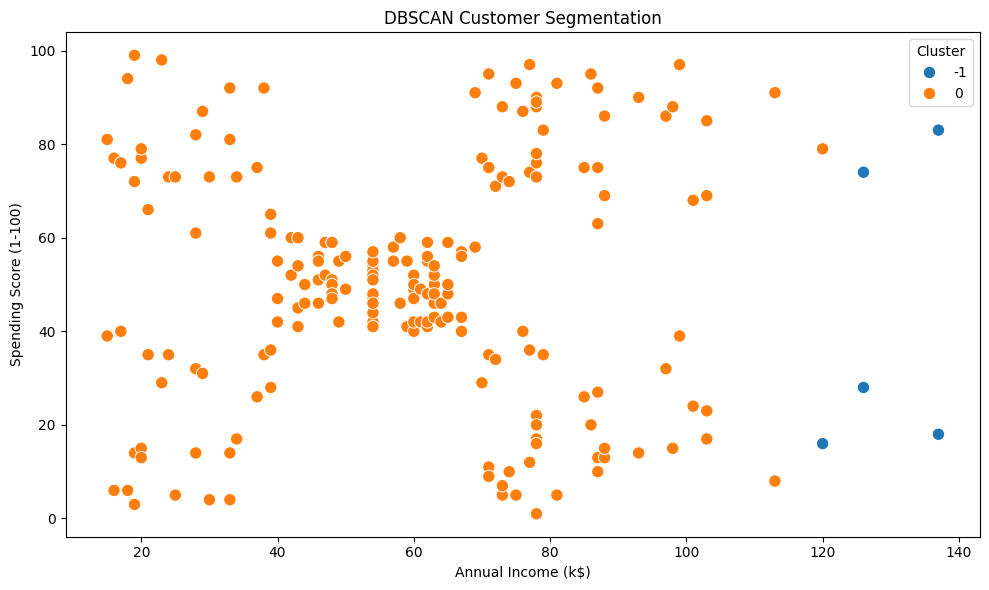

In [ ]:

# Set DBSCAN parameters
eps = 0.6
min_samples = 5

# Create and train the DBSCAN model
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples
)

cluster_labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the dataset
df['Cluster'] = cluster_labels

print("DBSCAN clustering completed successfully!")

print("\nCluster Labels:")
print(np.unique(cluster_labels))

print("\nFirst Five Rows with Cluster Labels:")
display(df.head())

# Visualize the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X.iloc[:, 0],
    y=X.iloc[:, 1],
    hue=cluster_labels,
    palette="tab10",
    s=80
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Customer Segmentation")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Identify clusters and noise points
unique_labels = set(cluster_labels)

n_clusters = len(unique_labels - {-1})
n_noise = int(np.sum(cluster_labels == -1))

print("Number of Clusters (excluding noise):", n_clusters)
print("Number of Noise Points:", n_noise)
print("Total Data Points:", len(cluster_labels))

print(
    "Noise Percentage:",
    round((n_noise / len(cluster_labels)) * 100, 2),
    "%"
)

# Calculate Silhouette Score
# Exclude noise points from the score
non_noise_mask = cluster_labels != -1
non_noise_labels = cluster_labels[non_noise_mask]
non_noise_data = X_scaled[non_noise_mask]

if (
    len(non_noise_labels) > 1
    and len(np.unique(non_noise_labels)) > 1
    and len(np.unique(non_noise_labels)) < len(non_noise_labels)
):
    score = silhouette_score(non_noise_data, non_noise_labels)
    print("Silhouette Score:", round(score, 4))
else:
    print(
        "Silhouette Score cannot be calculated: "
        "at least two non-noise clusters are required."
    )


Number of Clusters (excluding noise): 1
Number of Noise Points: 5
Total Data Points: 200
Noise Percentage: 2.5 %
Silhouette Score cannot be calculated: at least two non-noise clusters are required.


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Dataset with Cluster Labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
5,6,Female,22,17,76,0
6,7,Female,35,18,6,0
7,8,Female,23,18,94,0
8,9,Male,64,19,3,0
9,10,Female,30,19,72,0



Average Income and Spending Score by Cluster:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
-1,129.2,43.80
0,58.8,50.36



Number of Customers in Each Cluster:
Cluster
-1      5
 0    195
Name: count, dtype: int64

Number of Noise Points: 5

Noise Point Records:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
194,195,Female,47,120,16,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,-1
199,200,Male,30,137,83,-1


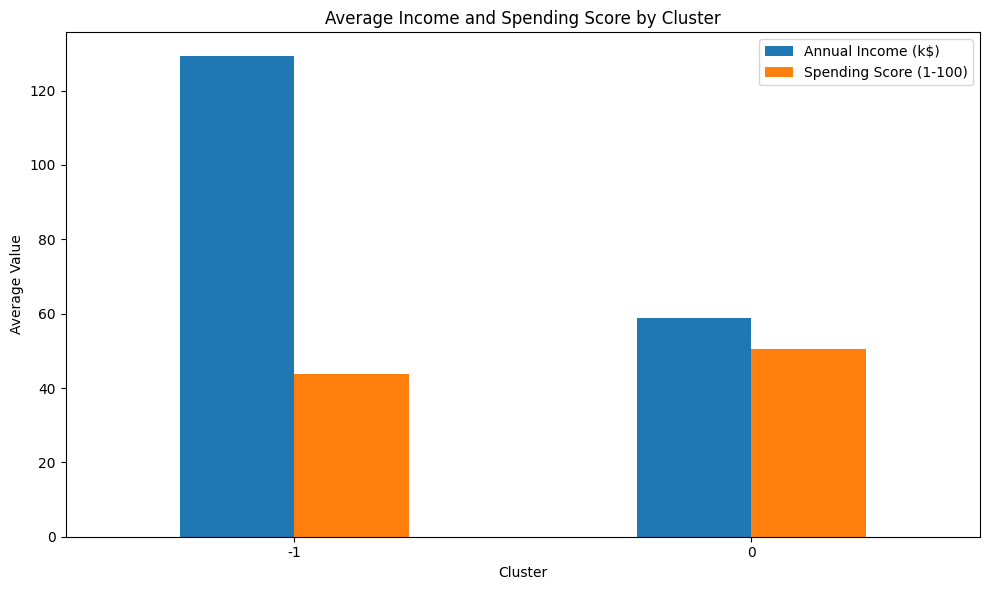

In [ ]:

# Display dataset with cluster labels
print("Dataset with Cluster Labels:")
display(df.head(10))

# Calculate mean statistics for each cluster
cluster_stats = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

print("\nAverage Income and Spending Score by Cluster:")
display(cluster_stats)

# Count customers in each cluster
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Separate noise points
noise_points = df[df['Cluster'] == -1]

print("\nNumber of Noise Points:", len(noise_points))

print("\nNoise Point Records:")
display(noise_points.head(10))

# Visualize cluster statistics
if not cluster_stats.empty:
    cluster_stats.plot(
        kind='bar',
        figsize=(10, 6)
    )

    plt.xlabel("Cluster")
    plt.ylabel("Average Value")
    plt.title("Average Income and Spending Score by Cluster")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.